# P27 freeze: real-TESS validation manifest, loader, download plan

Companion notebook to `README.md` in this folder. Running top-to-bottom regenerates every figure in `figures/` from the saved results in `data/` (or the referenced `runs/` directory).

In [1]:
# Setup: make the flat claude_files package importable and load shared helpers.
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REPO = Path.cwd()
while not (REPO / "claude_files").exists() and REPO != REPO.parent:
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "claude_files"))
REPORT = REPO / "reports" / "2026-11-19_p27-freeze"
FIG = REPORT / "figures"
DATA = REPORT / "data"
FIG.mkdir(exist_ok=True)

import evaluation as ev  # project-wide scoring convention (REL_TOL, outcome categories)


## Load the frozen manifest and the MAST metadata plan

In [2]:
m = pd.read_csv(REPO / "datasets" / "tess_validation_v1.csv")
FIG = REPO / "reports" / "2026-11-19_p27-freeze" / "figures"; DATA = REPO / "reports" / "2026-11-19_p27-freeze" / "data"
FIG.mkdir(exist_ok=True)
plan_path = DATA / "plan_per_star.csv"   # per star: files and MB at MAST (dry-run metadata), written by the dry run summary
plan = pd.read_csv(plan_path) if plan_path.exists() else None
LAB = ["rotator", "contaminant_eb", "nonrotator", "nonrotator_candidate", "expected_undetectable"]
COL = dict(rotator="#1b6ca8", contaminant_eb="#c0572b", nonrotator="#6a8f3a", nonrotator_candidate="#8a6fb3", expected_undetectable="#999999")
print(m.label.value_counts().to_string())

label
rotator                  268
nonrotator               100
contaminant_eb            50
expected_undetectable     40
nonrotator_candidate      22


## Figure 1: final mix, class x period bin
Rotators and EBs have a truth period and so a period bin; the negative blocks have none and are shown as blocks (split by `source`). Nothing lies beyond 71 d (the 70-180 d block is skipped).

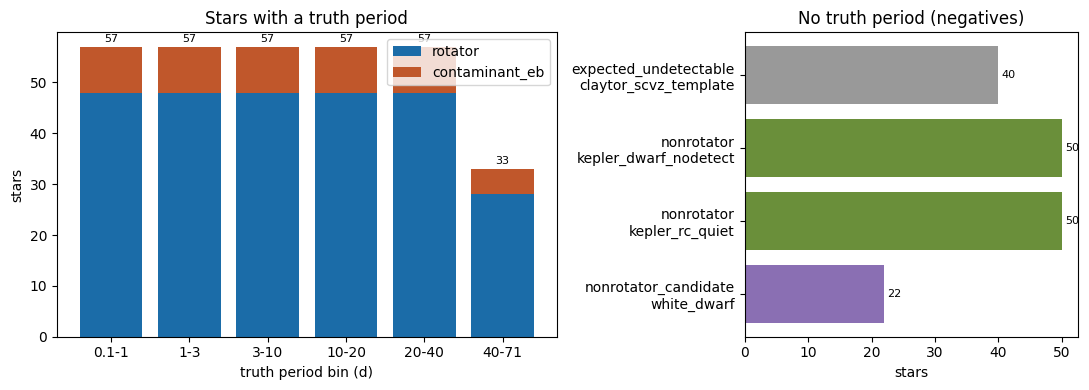

label        contaminant_eb  expected_undetectable  nonrotator  nonrotator_candidate  rotator
star_type                                                                                    
dwarf                    48                     40          50                     0      267
giant                     2                      0           0                     0        1
rc_giant                  0                      0          50                     0        0
white_dwarf               0                      0           0                    22        0


In [3]:
bins = ["0.1-1", "1-3", "3-10", "10-20", "20-40", "40-71"]
ct = pd.crosstab(m.pbin, m.label).reindex(bins).fillna(0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw=dict(width_ratios=[3, 2]))
b = np.zeros(len(bins))
for l in ["rotator", "contaminant_eb"]:
    ax[0].bar(bins, ct[l], bottom=b, color=COL[l], label=l); b += ct[l].values
for i, v in enumerate(b): ax[0].text(i, v + 1, int(v), ha="center", fontsize=8)
ax[0].set_xlabel("truth period bin (d)"); ax[0].set_ylabel("stars"); ax[0].legend(); ax[0].set_title("Stars with a truth period")
neg = m[m.truth_period.isna()].groupby(["label", "source"]).size().reset_index(name="n")
ax[1].barh([f"{a}\n{s}" for a, s in zip(neg.label, neg.source)], neg.n, color=[COL[l] for l in neg.label])
for i, v in enumerate(neg.n): ax[1].text(v + 0.5, i, v, va="center", fontsize=8)
ax[1].set_xlabel("stars"); ax[1].set_title("No truth period (negatives)"); ax[1].invert_yaxis()
fig.tight_layout(); fig.savefig(FIG / "mix_class_by_period.png", dpi=130); plt.show()
print(pd.crosstab(m.star_type, m.label).to_string())

## Figure 2: sector coverage per star
FFI sectors TESS observed the star (`n_sectors`, from TESSCut) against the TESS-SPOC / QLP files that exist at MAST. Few sectors mean long periods cannot be tested whatever the method.

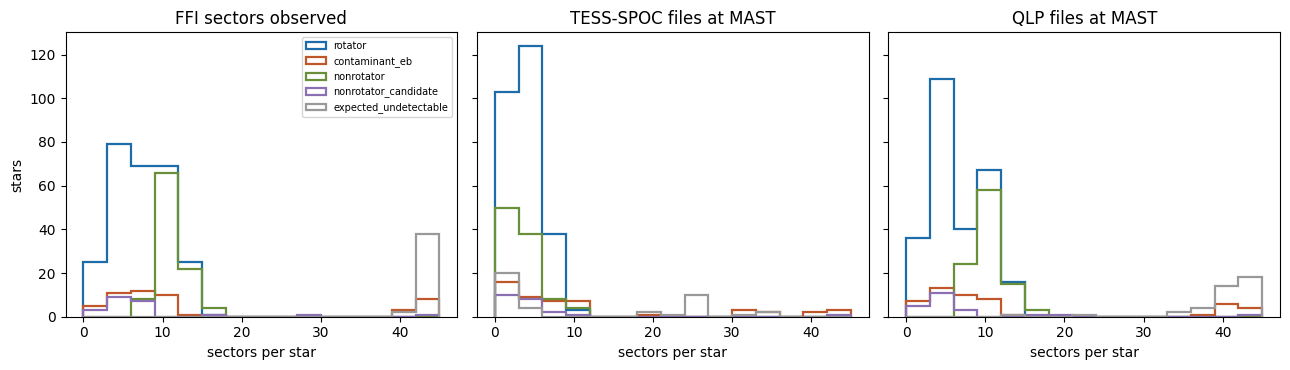

rotators with <=2 FFI sectors: 25 ; median FFI sectors: 6.0
                       n_sectors  n_tess_spoc  n_qlp
label                                               
contaminant_eb               7.0          6.0    7.0
expected_undetectable       44.0          1.5   41.0
nonrotator                  10.0          2.5    9.0
nonrotator_candidate         5.0          3.0    4.0
rotator                      6.0          3.0    5.0


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for a, (col, ttl) in zip(ax, [("n_sectors", "FFI sectors observed"), ("n_tess_spoc", "TESS-SPOC files at MAST"), ("n_qlp", "QLP files at MAST")]):
    for l in LAB:
        a.hist(m.loc[m.label == l, col], bins=np.arange(0, 47, 3), histtype="step", lw=1.6, color=COL[l], label=l)
    a.set_title(ttl); a.set_xlabel("sectors per star")
ax[0].set_ylabel("stars"); ax[0].legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "sector_coverage.png", dpi=130); plt.show()
r = m[m.label == "rotator"]
print("rotators with <=2 FFI sectors:", int((r.n_sectors <= 2).sum()), "; median FFI sectors:", r.n_sectors.median())
print(m.groupby("label")[["n_sectors", "n_tess_spoc", "n_qlp"]].median().to_string())

## Figure 3: SPOC vs QLP availability
Per class, the share of stars whose best product is TESS-SPOC, QLP only (fallback) or nothing. `product_primary` comes from the manifest counts. Stars with `none` cannot be scored.

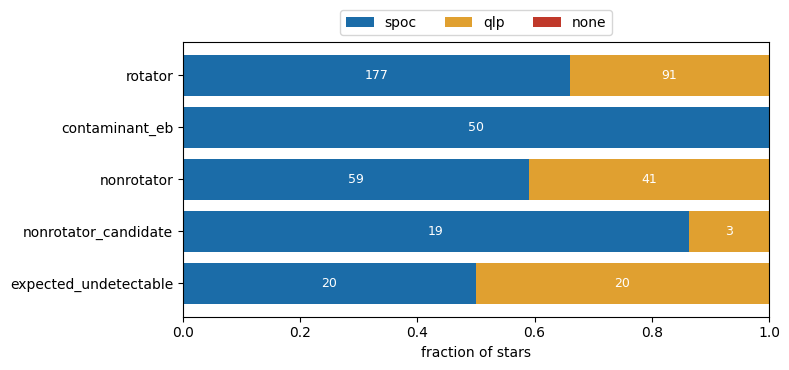

product_primary        spoc  qlp  none
label                                 
rotator                 177   91     0
contaminant_eb           50    0     0
nonrotator               59   41     0
nonrotator_candidate     19    3     0
expected_undetectable    20   20     0
scorable: 480 of 480


In [5]:
ct = pd.crosstab(m.label, m.product_primary).reindex(index=LAB, columns=["spoc", "qlp", "none"], fill_value=0)
frac = ct.div(ct.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(8, 3.8))
left = np.zeros(len(LAB))
for c, colr in zip(["spoc", "qlp", "none"], ["#1b6ca8", "#e0a030", "#c0392b"]):
    ax.barh(LAB, frac[c], left=left, color=colr, label=c)
    for i, (v, lft) in enumerate(zip(frac[c], left)):
        if v > 0.06: ax.text(lft + v / 2, i, f"{int(ct[c].iloc[i])}", ha="center", va="center", color="w", fontsize=9)
    left += frac[c].values
ax.set_xlabel("fraction of stars"); ax.invert_yaxis(); ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(); fig.savefig(FIG / "spoc_vs_qlp_availability.png", dpi=130); plt.show()
print(ct.to_string()); print("scorable:", int(m.scorable.sum()), "of", len(m))

## Download size from the MAST metadata dry run (if `data/plan_per_star.csv` exists)

In [6]:
if plan is not None:
    print(plan.groupby("product")[["n_files", "mb"]].sum().round(1).to_string())
    print("total GB:", round(plan.mb.sum() / 1e3, 2), "files:", int(plan.n_files.sum()))
else:
    print("no plan table saved")

         n_files      mb
product                 
qlp         1903   769.8
spoc        2175  1286.9
total GB: 2.06 files: 4078


## Figure 4: the locked 30% holdout
Stars per label and period bin, validation vs holdout. The holdout (`split == "holdout"`) is never scored without Rae's word.

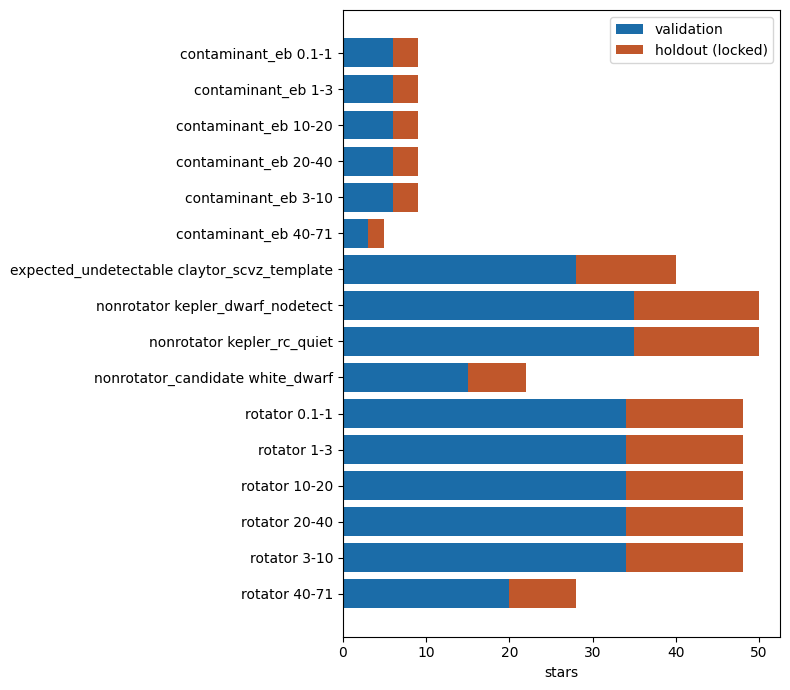

split                  holdout  validation
label                                     
contaminant_eb              17          33
expected_undetectable       12          28
nonrotator                  30          70
nonrotator_candidate         7          15
rotator                     78         190
holdout fraction: 0.3


In [7]:
key = np.where(m.pbin.fillna("") != "", m.label + " " + m.pbin.fillna(""), m.label + " " + m.source)
ct = pd.crosstab(key, m.split)
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(ct.index, ct["validation"], color="#1b6ca8", label="validation")
ax.barh(ct.index, ct["holdout"], left=ct["validation"], color="#c0572b", label="holdout (locked)")
ax.set_xlabel("stars"); ax.legend(); ax.invert_yaxis()
fig.tight_layout(); fig.savefig(FIG / "holdout_split.png", dpi=130); plt.show()
print(m.groupby("label").split.value_counts().unstack().to_string()); print("holdout fraction:", round((m.split == "holdout").mean(), 3))

## Figure 5: replacements and Gaia pulsator flags
Where the 79 replacement stars came from (rotators by cluster) and which stars carry a Gaia pulsator class.

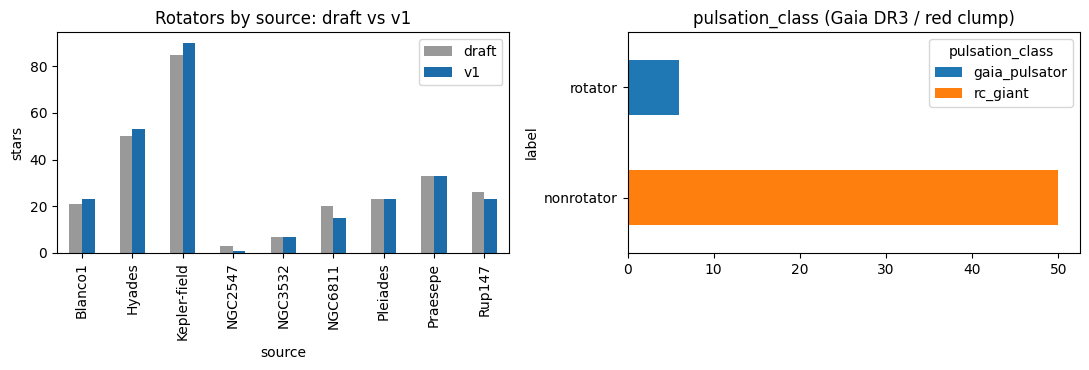

79 replacements: {('contaminant_eb', 'prsa2022_eb'): 7, ('expected_undetectable', 'claytor_scvz_template'): 15, ('nonrotator', 'kepler_dwarf_nodetect'): 32, ('nonrotator_candidate', 'white_dwarf'): 2, ('rotator', 'Blanco1'): 2, ('rotator', 'Hyades'): 3, ('rotator', 'Kepler-field'): 17, ('rotator', 'NGC3532'): 1}
          star_id    label   source       gaia_class
178  TIC270957367  rotator  NGC6811  DSCT|GDOR|SXPHE
181  TIC270957797  rotator  NGC6811  DSCT|GDOR|SXPHE
184  TIC271041138  rotator  NGC6811  DSCT|GDOR|SXPHE
185  TIC271041209  rotator  NGC6811  DSCT|GDOR|SXPHE
186  TIC271165608  rotator  NGC6811  DSCT|GDOR|SXPHE
188  TIC271425191  rotator  NGC6811  DSCT|GDOR|SXPHE


In [8]:
d0 = pd.read_csv(REPO / "datasets" / "proposed" / "p27_validation_draft.csv")
rep = pd.read_csv(REPO / "datasets" / "proposed" / "p27_v1_replacements.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
r0 = d0[d0.label == "rotator"].source.value_counts(); r1 = m[m.label == "rotator"].source.value_counts()
x = pd.DataFrame({"draft": r0, "v1": r1}).fillna(0)
x.plot.bar(ax=ax[0], color=["#999999", "#1b6ca8"]); ax[0].set_title("Rotators by source: draft vs v1"); ax[0].set_ylabel("stars")
pc = pd.crosstab(m.label, m.pulsation_class.replace("", "none"))
pc.plot.barh(stacked=True, ax=ax[1]); ax[1].set_title("pulsation_class (Gaia DR3 / red clump)")
fig.tight_layout(); fig.savefig(FIG / "replacements_and_pulsators.png", dpi=130); plt.show()
print(len(rep), "replacements:", rep.groupby(["label", "source"]).size().to_dict())
print(m[m.gaia_pulsator][["star_id", "label", "source", "gaia_class"]].to_string())